# Assignment 12: Customer Segmentation using K-Means Clustering
**Aim:** Perform customer segmentation on the Mall Customers dataset using the K-Means clustering algorithm based on 'Annual Income (k$)' and 'Spending Score (1-100)', with the number of clusters set to 5 ($K=5$). Visualize the resulting clusters using a scatter plot.  
**Tools / Libraries:** `pandas`, `numpy`, `matplotlib`, `seaborn`, `scikit-learn` (`sklearn.cluster.KMeans`)  
**Programming Platform / Language:** Jupyter Notebook, Python

## Theory & Task Overview

### K-Means Clustering
K-Means is an unsupervised machine learning algorithm used to partition $n$ observations into $K$ distinct clusters in which each observation belongs to the cluster with the nearest mean (cluster centroid).
* **Application in Marketing:** Customer segmentation helps businesses divide their customer base into groups of individuals that share similar characteristics (e.g., income level and spending behavior), enabling targeted marketing strategies.
* **Key Features Used:** 
  1. `Annual Income (k$)`
  2. `Spending Score (1-100)`
* **Number of Clusters ($K$):** Set to `5`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the Mall Customers dataset
df = pd.read_csv('Mall_Customers.csv')

# 2. Display the first few rows to inspect columns
print("Dataset Preview:")
display(df.head())

Dataset Preview:


,CustomerID,Gender,Age,Education,Annual Income (k$),Spending Score (1-100)
0,1,M,19,High School,15,39
1,2,M,21,Graduate,15,81
2,3,F,20,Graduate,16,6
3,4,F,23,High School,16,77
4,5,F,31,Uneducated,17,40


200

---
## Model Implementation: K-Means Clustering ($K=5$)

In [2]:
from sklearn.cluster import KMeans

# 1. Select the required features for clustering
# Features: 'Annual Income (k$)' and 'Spending Score (1-100)'
X = df[['Annual Income (k$)', 'Spending Score (1-100)']].values

# 2. Initialize K-Means with 5 clusters
kmeans = KMeans(n_clusters=5, init='k-means++', max_iter=300, n_init=10, random_state=42)

# 3. Fit the model and predict cluster labels for each customer
cluster_labels = kmeans.fit_predict(X)

# 4. Add cluster labels back to the dataframe for analysis
df['Cluster'] = cluster_labels

print("K-Means clustering completed successfully!")
print(f"Cluster counts:\n{df['Cluster'].value_counts()}")

K-Means clustering completed successfully!
Cluster counts:
Cluster
0    81
1    39
3    35
4    23
2    22
Name: count, dtype: int64


---
## Cluster Segmentation Plot
Plotting the customer segments based on Annual Income vs. Spending Score along with cluster centroids.

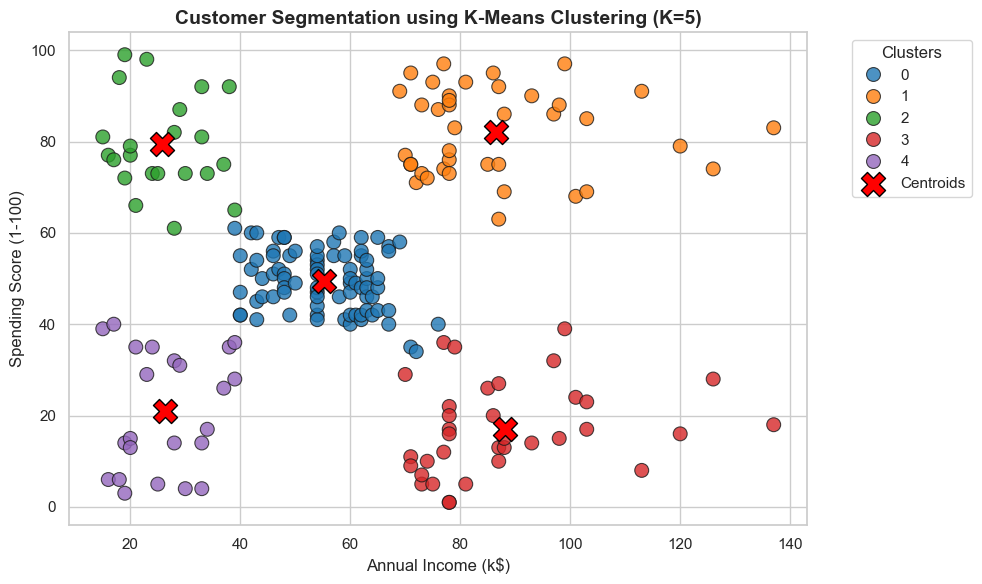

In [3]:
# Set plot style
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")

# Create scatter plot of the clusters
sns.scatterplot(
    x='Annual Income (k$)', 
    y='Spending Score (1-100)', 
    hue='Cluster', 
    data=df, 
    palette='tab10', 
    s=100, 
    alpha=0.8, 
    edgecolor='k'
)

# Plot the cluster centroids
centroids = kmeans.cluster_centers_
plt.scatter(
    centroids[:, 0], 
    centroids[:, 1], 
    s=300, 
    c='red', 
    marker='X', 
    label='Centroids', 
    edgecolors='black'
)

plt.title('Customer Segmentation using K-Means Clustering (K=5)', fontsize=14, fontweight='bold')
plt.xlabel('Annual Income (k$)', fontsize=12)
plt.ylabel('Spending Score (1-100)', fontsize=12)
plt.legend(title='Clusters', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()